# LTV and Liquidation Risk: Morpho vs Aave

**What is LTV?** Loan-to-value is the ratio of a borrower's debt to their
collateral value, expressed as a percentage. Every lending market also has a
**liquidation LTV** (`lltv`): the ceiling at which the protocol is allowed to
seize and sell the collateral. The gap between a position's current LTV and
its liquidation LTV is its **buffer** — how many percentage points of price
movement it can absorb before liquidation.

This notebook asks two questions, separately for whales and everyone else,
and separately for Morpho and Aave:

1. **Risk to the position holder** — how close is this specific holder to
   getting liquidated, and what would it lose?
2. **Risk to other actors** — if this wallet gets liquidated, does it create
   knock-on effects (price impact, cascading liquidations) for people who
   have no position with that wallet at all?

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE = "#4C72B0", "#DD8452"   # non-whale / whale, used consistently throughout

## Load data

Morpho markets are isolated: each position has its own `ltv_percentage` and
`lltv_percentage`, so liquidation distance is directly known per wallet.

Aave sUSDe is a shared, cross-collateral pool. There is no reliable per-wallet
liquidation threshold, only a pool-wide one, so Aave risk is framed differently
below (see the Aave section for the assumption this relies on).

In [71]:
morpho_files = {
    "sUSDe":     "../from_dune/borrowers/morpho_borrowers_susde.csv",
    "sUSDS":     "../from_dune/borrowers/morpho_borrowers_susds.csv",
    "syrupUSDC": "../from_dune/borrowers/morpho_borrowers_syrup.csv",
}

tokens = list(morpho_files.keys())

morpho_dfs = {name: pd.read_csv(path).assign(asset=name) for name, path in morpho_files.items()}
morpho_borrowers = pd.concat(morpho_dfs.values(), ignore_index=True)

print(f"Morpho: {len(morpho_borrowers)} positions, {morpho_borrowers['address'].nunique()} unique wallets")

Morpho: 350 positions, 318 unique wallets


In [72]:
aave_raw = pd.read_csv("../from_dune/borrowers/aave_borrowers_susde.csv")

aave_borrowers = (
    aave_raw.groupby("address")
    .agg(collateral_value_usd=("collateral_value_usd", "first"),
         borrowed_value=("borrowed_value", "sum"))
    .reset_index()
)
aave_borrowers["ltv_percentage"] = 100 * aave_borrowers["borrowed_value"] / aave_borrowers["collateral_value_usd"]

print(f"Aave sUSDe: {len(aave_borrowers)} wallets, {(aave_borrowers['borrowed_value'] > 0).sum()} with active debt")

Aave sUSDe: 1160 wallets, 361 with active debt


## Tag whales

Whale = address holding more than 1,000,000 YBS in total (wallet + protocol
balances). This matters for risk, since a whale's liquidation moves far more
collateral than a retail liquidation.

In [73]:
aave_whales = pd.read_csv("../input/aave_whales.csv")
morpho_whales = pd.read_csv("../input/morpho_whales.csv")

aave_borrowers["is_whale"] = aave_borrowers["address"].isin(
    aave_whales.loc[aave_whales["asset"] == "sUSDe", "wallet"]
)

morpho_whale_keys = set(zip(morpho_whales["wallet"], morpho_whales["asset"]))
morpho_borrowers["is_whale"] = [
    (addr, asset) in morpho_whale_keys
    for addr, asset in zip(morpho_borrowers["address"], morpho_borrowers["asset"])
]

## Part 1 — Morpho: distance to liquidation

`ltv_buffer = lltv_percentage - ltv_percentage`: the percentage points of LTV
increase a position can absorb before it hits its market's liquidation
threshold. A buffer near 0 means the position is one small price move away
from liquidation.

In [74]:
morpho_active = morpho_borrowers[morpho_borrowers["ltv_percentage"] >= 0.5].copy()
morpho_active["ltv_buffer"] = morpho_active["lltv_percentage"] - morpho_active["ltv_percentage"]

def hf_band(row):
    if row["hf_market"] < 1.05:
        return "critical (<1.05)"
    elif row["hf_market"] < 1.2:
        return "high_risk (1.05-1.2)"
    elif row["hf_market"] < 1.5:
        return "moderate (1.2-1.5)"
    else:
        return "safe (>1.5)"

morpho_active["risk_band"] = morpho_active.apply(hf_band, axis=1)

risk_summary = (
    morpho_active.groupby(["asset", "risk_band"])
    .agg(positions=("address", "count"),
         whale_positions=("is_whale", "sum"),
         collateral_usd=("collateral_value_usd", "sum"))
    .reset_index()
)
risk_summary

,asset,risk_band,positions,whale_positions,collateral_usd
0,sUSDS,critical (<1.05),5,1,5.362890e+06
1,sUSDS,high_risk (1.05-1.2),68,14,6.132489e+07
2,sUSDS,moderate (1.2-1.5),9,0,2.620812e+06
3,sUSDS,safe (>1.5),3,0,3.377227e+04
4,sUSDe,high_risk (1.05-1.2),74,10,5.061091e+07
5,sUSDe,moderate (1.2-1.5),37,1,5.039571e+06
6,sUSDe,safe (>1.5),31,0,1.358065e+05
7,syrupUSDC,high_risk (1.05-1.2),58,20,1.236606e+08
8,syrupUSDC,moderate (1.2-1.5),13,1,1.035173e+07
9,syrupUSDC,safe (>1.5),6,3,4.572630e+06


In [75]:
below_1_morpho = morpho_active[morpho_active["hf_market"] < 1]

n_below_1 = len(below_1_morpho)
n_whale_below_1 = below_1_morpho["is_whale"].sum()
usd_below_1 = below_1_morpho["collateral_value_usd"].sum()

print(f"{n_below_1} Morpho positions have hf_market < 1 ({n_whale_below_1} whales), "
      f"holding ${usd_below_1:,.0f} in collateral")

if n_below_1 > 0:
    print(below_1_morpho.groupby("asset")["hf_market"].describe())
    print(below_1_morpho[["address", "asset", "market_label", "hf_market", "ltv_percentage", "lltv_percentage", "collateral_value_usd"]])

0 Morpho positions have hf_market < 1 (0 whales), holding $0 in collateral


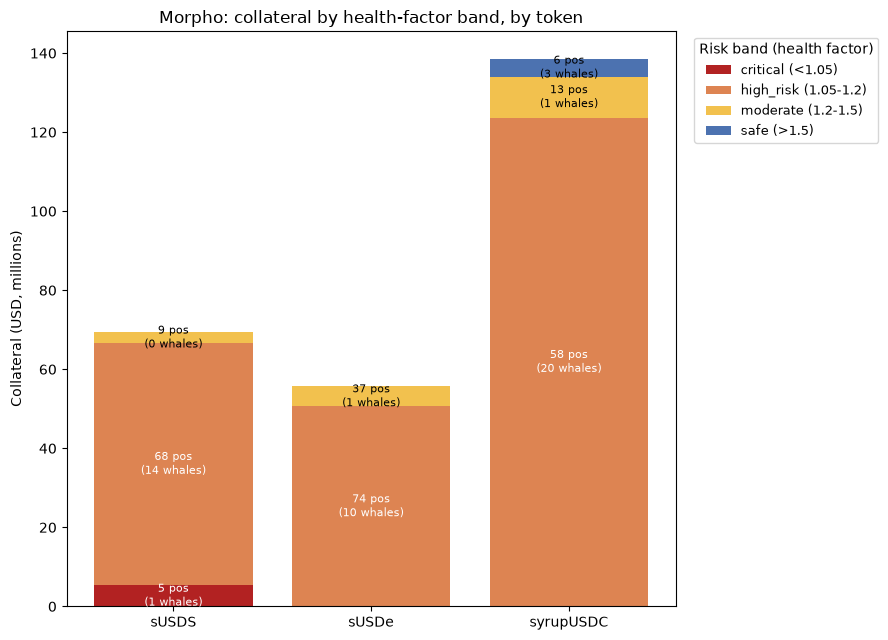

In [76]:
band_order = ["critical (<1.05)", "high_risk (1.05-1.2)", "moderate (1.2-1.5)", "safe (>1.5)"]
band_colors = {
    "critical (<1.05)": "#B22222",
    "high_risk (1.05-1.2)": "#DD8452",
    "moderate (1.2-1.5)": "#F2C14E",
    "safe (>1.5)": "#4C72B0",
}

collateral_pivot = (
    risk_summary.pivot(index="asset", columns="risk_band", values="collateral_usd")
    .reindex(columns=band_order).fillna(0) / 1e6
)
positions_pivot = (
    risk_summary.pivot(index="asset", columns="risk_band", values="positions")
    .reindex(columns=band_order).fillna(0)
)
whales_pivot = (
    risk_summary.pivot(index="asset", columns="risk_band", values="whale_positions")
    .reindex(columns=band_order).fillna(0)
)

fig, ax = plt.subplots(figsize=(9, 6.5))
bottom = np.zeros(len(collateral_pivot))

for band in band_order:
    heights = collateral_pivot[band].values
    ax.bar(collateral_pivot.index, heights, bottom=bottom, label=band, color=band_colors[band])

    for i, (asset, height) in enumerate(zip(collateral_pivot.index, heights)):
        if height > 1:
            n_pos = int(positions_pivot.loc[asset, band])
            n_whale = int(whales_pivot.loc[asset, band])
            ax.annotate(
                f"{n_pos} pos\n({n_whale} whales)",
                xy=(i, bottom[i] + height / 2), ha="center", va="center", fontsize=8,
                color="white" if band in ("critical (<1.05)", "high_risk (1.05-1.2)") else "black",
            )
    bottom += heights

ax.set_ylabel("Collateral (USD, millions)")
ax.set_title("Morpho: collateral by health-factor band, by token")
ax.legend(title="Risk band (health factor)", loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
plt.tight_layout()
plt.savefig("../output/morpho_risk_band_by_token.png", dpi=300, bbox_inches="tight")
plt.show()

### Risk to whales (Morpho)

If a whale position sits in the critical band, the loss isn't just theirs:
their collateral is large enough that the forced sale can itself move the
price of the underlying token.

In [77]:
at_risk = morpho_active[morpho_active["risk_band"].isin(["critical (<1.05)", "high_risk (1.05-1.2)"])]

n_whale = at_risk["is_whale"].sum()
usd_whale = at_risk.loc[at_risk["is_whale"], "collateral_value_usd"].sum()
usd_total = at_risk["collateral_value_usd"].sum()

print(f"{n_whale} whale positions are in the critical/high-risk bands, "
      f"holding ${usd_whale:,.0f} of ${usd_total:,.0f} total collateral at risk "
      f"({100 * usd_whale / usd_total:.1f}%)")

45 whale positions are in the critical/high-risk bands, holding $224,271,153 of $240,959,267 total collateral at risk (93.1%)


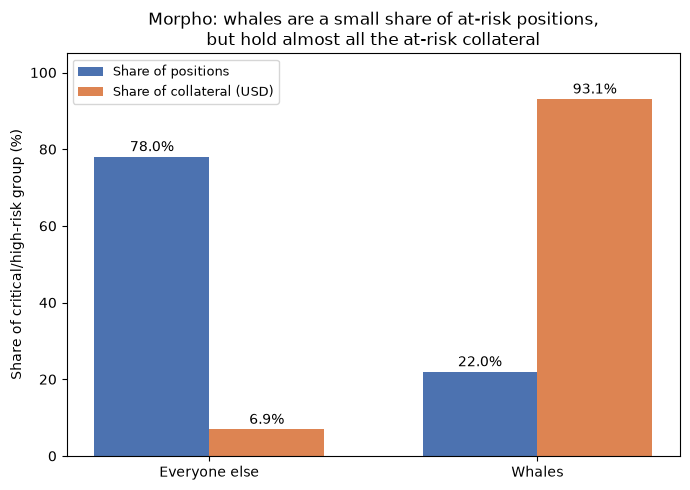

In [78]:
whale_summary = (
    at_risk.groupby("is_whale")
    .agg(positions=("address", "count"), collateral_usd=("collateral_value_usd", "sum"))
    .reindex([False, True])  # ensure order: everyone else, then whales
)

pct_positions = 100 * whale_summary["positions"] / whale_summary["positions"].sum()
pct_collateral = 100 * whale_summary["collateral_usd"] / whale_summary["collateral_usd"].sum()

labels = ["Everyone else", "Whales"]
x = np.arange(2)
width = 0.35

fig, ax = plt.subplots(figsize=(7, 5))
bars1 = ax.bar(x - width/2, pct_positions, width, label="Share of positions", color=BLUE)
bars2 = ax.bar(x + width/2, pct_collateral, width, label="Share of collateral (USD)", color=ORANGE)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.annotate(f"{bar.get_height():.1f}%", xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Share of critical/high-risk group (%)")
ax.set_ylim(0, 105)
ax.set_title("Morpho: whales are a small share of at-risk positions,\nbut hold almost all the at-risk collateral")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("../output/morpho_whale_risk_share.png", dpi=300, bbox_inches="tight")
plt.show()

### Risk to other actors (Morpho)

A liquidation forces a sale of collateral into the market. If enough
liquidations land in the same market at once, the resulting sell pressure can
push the collateral price down further, pushing more positions in that same
market past their own liquidation threshold. This is a cascade risk, and it
falls on every borrower in that market, not just the one being liquidated.
Concentration by market tells us where that risk is most exposed.

In [79]:
at_risk_by_market = (
    at_risk.groupby(["asset", "market_label"])
    .agg(positions=("address", "count"),
         collateral_at_risk_usd=("collateral_value_usd", "sum"),
         avg_leverage=("leverage_market", "mean"))
    .reset_index()
    .sort_values("collateral_at_risk_usd", ascending=False)
)
at_risk_by_market

,asset,market_label,positions,collateral_at_risk_usd,avg_leverage
11,syrupUSDC,PYUSD,14,7.768234e+07,7.390474
2,sUSDS,USDT,62,6.238305e+07,13.021046
5,sUSDe,PYUSD,12,4.134966e+07,7.758021
10,syrupUSDC,AUSD,17,2.367183e+07,8.085681
12,syrupUSDC,RLUSD,19,2.225318e+07,8.395890
8,sUSDe,USDtb,17,8.490175e+06,7.662988
0,sUSDS,AUSD,10,4.280935e+06,9.375254
9,sUSDe,msUSD,16,5.093791e+05,8.133929
7,sUSDe,USDT,8,1.981878e+05,9.690172
4,sUSDe,DAI,19,6.343293e+04,9.667347


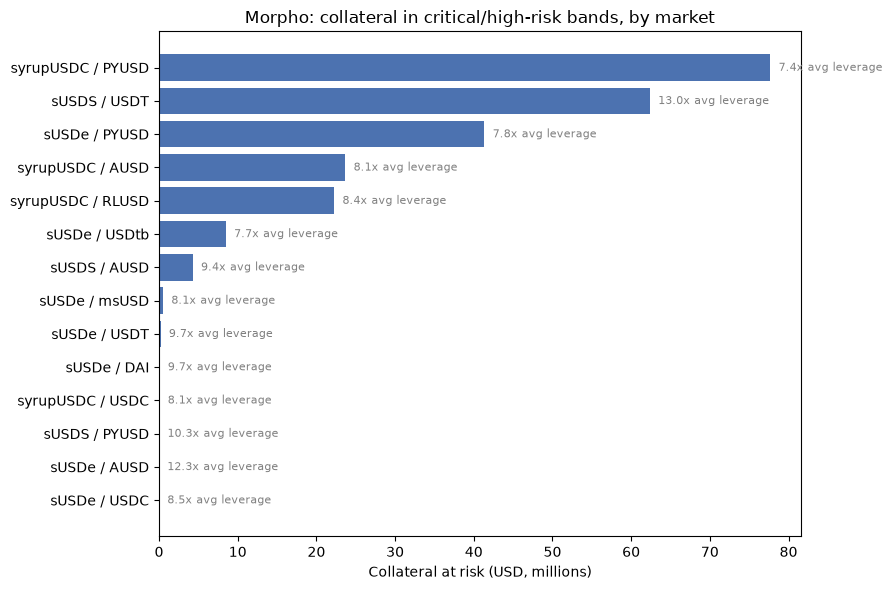

In [80]:
plot_data = at_risk_by_market.sort_values("collateral_at_risk_usd", ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(
    plot_data["asset"] + " / " + plot_data["market_label"],
    plot_data["collateral_at_risk_usd"] / 1e6,
    color=BLUE,
)
for bar, lev in zip(bars, plot_data["avg_leverage"]):
    ax.annotate(f"{lev:.1f}x avg leverage", xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color="gray")

ax.set_xlabel("Collateral at risk (USD, millions)")
ax.set_title("Morpho: collateral in critical/high-risk bands, by market")
plt.tight_layout()
plt.savefig("../output/morpho_at_risk_by_market.png", dpi=300, bbox_inches="tight")
plt.show()

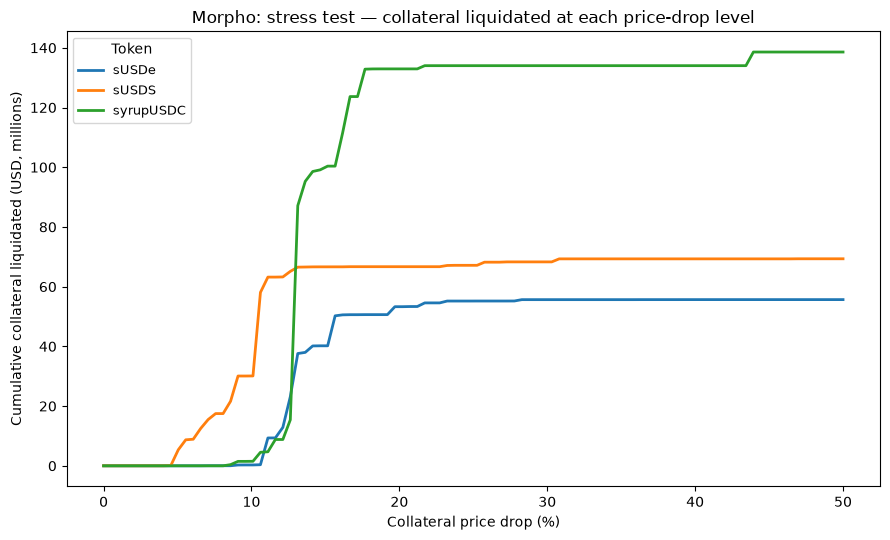

In [81]:
morpho_active["critical_shock"] = 1 - 1 / morpho_active["hf_market"]
morpho_active = morpho_active[morpho_active["critical_shock"] > 0]

shocks = np.linspace(0, 0.5, 100)  # simulate 0% to 50% price drops

fig, ax = plt.subplots(figsize=(9, 5.5))

for asset in tokens:
    sub = morpho_active[morpho_active["asset"] == asset]
    cumulative = [sub.loc[sub["critical_shock"] <= s, "collateral_value_usd"].sum() / 1e6 for s in shocks]
    ax.plot(shocks * 100, cumulative, label=asset, linewidth=2)

ax.set_xlabel("Collateral price drop (%)")
ax.set_ylabel("Cumulative collateral liquidated (USD, millions)")
ax.set_title("Morpho: stress test — collateral liquidated at each price-drop level")
ax.legend(title="Token", fontsize=9)
plt.tight_layout()
plt.savefig("../output/morpho_price_shock_stress_test.png", dpi=300, bbox_inches="tight")
plt.show()

## Part 2 Aave: utilization as a proxy for risk

Aave sUSDe is a shared pool, so there's no per-wallet liquidation threshold in
this data, only a pool-wide one. As a simplifying assumption, we use
utilization (`borrowed_value / collateral_value_usd`) as a proxy: the higher
it runs relative to the pool's liquidation threshold, the less room a wallet
has before liquidation. This assumption should be flagged wherever it's cited,
since it treats all sUSDe collateral as if it shared one threshold, which
understates risk for wallets holding riskier non-stable debt.

## Load and filter data

In [82]:
non_stablecoins = {"WETH", "cbBTC", "weETH", "wstETH", "CRV", "rETH"}
aave_raw = pd.read_csv("../from_dune/borrowers/aave_borrowers_susde.csv")

n_rows_before = len(aave_raw)
aave_stable_raw = aave_raw[~aave_raw["debt_symbol"].isin(non_stablecoins)].copy()
n_rows_after = len(aave_stable_raw)

aave_borrowers = (
    aave_stable_raw.groupby("address")
    .agg(collateral_value_usd=("collateral_value_usd", "first"),
         borrowed_value=("borrowed_value", "sum"))
    .reset_index()
)

aave_borrowers = aave_borrowers[aave_borrowers["borrowed_value"] > 0].copy()

print(f"Aave rows: {n_rows_before} total, {n_rows_after} after dropping non-stablecoin debt rows "
      f"({n_rows_before - n_rows_after} rows removed)")
print(f"Aave sUSDe (stablecoin debt only): {len(aave_borrowers)} wallets, "
      f"{(aave_borrowers['borrowed_value'] > 0).sum()} with active stablecoin debt")

Aave rows: 2356 total, 2149 after dropping non-stablecoin debt rows (207 rows removed)
Aave sUSDe (stablecoin debt only): 353 wallets, 353 with active stablecoin debt


## Get HF's of all addresses

In [83]:
from dotenv import load_dotenv
from web3 import Web3
import pandas as pd
from concurrent.futures import ThreadPoolExecutor, as_completed
import os
import time

load_dotenv(dotenv_path="../.env")

RPC_URL = os.environ["ALCHEMY_RPC_URL"]
POOL_ADDRESS = "0x87870Bca3F3fD6335C3F4ce8392D69350B4fA4E2"

POOL_ABI = [{
    "inputs": [{"internalType": "address", "name": "user", "type": "address"}],
    "name": "getUserAccountData",
    "outputs": [
        {"name": "totalCollateralBase", "type": "uint256"},
        {"name": "totalDebtBase", "type": "uint256"},
        {"name": "availableBorrowsBase", "type": "uint256"},
        {"name": "currentLiquidationThreshold", "type": "uint256"},
        {"name": "ltv", "type": "uint256"},
        {"name": "healthFactor", "type": "uint256"},
    ],
    "stateMutability": "view", "type": "function"
}]

w3 = Web3(Web3.HTTPProvider(RPC_URL, request_kwargs={"timeout": 20}))
pool = w3.eth.contract(address=Web3.to_checksum_address(POOL_ADDRESS), abi=POOL_ABI)

addresses = aave_borrowers["address"].unique().tolist()
print(f"Fetching health factor for {len(addresses)} addresses...")

def fetch_one(addr, max_retries=5):
    for attempt in range(max_retries):
        try:
            data = pool.functions.getUserAccountData(Web3.to_checksum_address(addr)).call()
            return {
                "address": addr,
                "total_collateral_base": data[0] / 1e8,
                "total_debt_base": data[1] / 1e8,
                "liquidation_threshold_pct": data[3] / 100,
                "ltv_pct": data[4] / 100,
                "health_factor": data[5] / 1e18,
            }
        except Exception as e:
            if "429" in str(e) and attempt < max_retries - 1:
                time.sleep(2 ** attempt)
                continue
            return {"address": addr, "error": str(e)}

results = []
with ThreadPoolExecutor(max_workers=4) as executor:  # lower concurrency to avoid tripping the limit again
    futures = {executor.submit(fetch_one, addr): addr for addr in addresses}
    for i, future in enumerate(as_completed(futures)):
        results.append(future.result())
        if (i + 1) % 100 == 0:
            print(f"  {i + 1}/{len(addresses)} done")

results_df = pd.DataFrame(results)
failed = results_df[results_df.get("error").notna()] if "error" in results_df else pd.DataFrame()
aave_health_factors = results_df[results_df.get("error").isna()] if "error" in results_df else results_df

print(f"{len(aave_health_factors)} succeeded, {len(failed)} failed")
if len(failed) > 0:
    print(failed["error"].value_counts())

aave_health_factors.to_csv("../from_dune/borrowers/aave_health_factors_susde.csv", index=False)
aave_health_factors.head()

Fetching health factor for 353 addresses...


KeyboardInterrupt: 

## Filter out 100% stablecoins debt addresses

In [45]:
stablecoins = {"USDT", "USDC", "USDe", "GHO", "USDS", "USDtb", "DAI", "PYUSD", "AUSD", "RLUSD", "msUSD"}

total_debt_all = aave_raw.groupby("address")["borrowed_value"].sum().rename("total_debt_all")

total_debt_stable = (
    aave_raw[aave_raw["debt_symbol"].isin(stablecoins)]
    .groupby("address")["borrowed_value"].sum().rename("total_debt_stable")
)

wallet_debt_check = pd.concat([total_debt_all, total_debt_stable], axis=1).fillna(0)
wallet_debt_check["is_stablecoin_only"] = (
    wallet_debt_check["total_debt_stable"] >= wallet_debt_check["total_debt_all"] * 0.999  # tolerance for rounding
)

stablecoin_only_wallets = wallet_debt_check[wallet_debt_check["is_stablecoin_only"]].index

print(f"{len(stablecoin_only_wallets)} of {len(wallet_debt_check)} wallets are 100% stablecoin debt "
      f"(out of {wallet_debt_check['total_debt_all'].gt(0).sum()} wallets with any debt at all)")

1134 of 1160 wallets are 100% stablecoin debt (out of 361 wallets with any debt at all)


## Merge HF into stablecoin wallet subset, check outliners

In [46]:
# 3. Merge real health factor onto the stablecoin-only wallet subset
aave_hf_stable = aave_health_factors[
    aave_health_factors["address"].isin(stablecoin_only_wallets)
].merge(
    aave_borrowers[["address", "is_whale"]].drop_duplicates() if "is_whale" in aave_borrowers.columns else pd.DataFrame(columns=["address", "is_whale"]),
    on="address", how="left"
)

aave_hf_stable_active = aave_hf_stable[aave_hf_stable["total_debt_base"] > 0].copy()

print(f"{len(aave_hf_stable)} wallets: 100% stablecoin debt, with real Aave health factor")
print(f"{len(aave_hf_stable_active)} of those have active debt (total_debt_base > 0)")
aave_hf_stable_active["health_factor"].describe()

1127 wallets: 100% stablecoin debt, with real Aave health factor
373 of those have active debt (total_debt_base > 0)


count    3.730000e+02
mean     1.287727e+04
std      1.677911e+05
min      8.607719e-01
25%      1.041379e+00
50%      1.204426e+00
75%      1.698484e+00
max      2.905536e+06
Name: health_factor, dtype: float64

In [47]:
extreme_hf = aave_hf_stable_active[aave_hf_stable_active["health_factor"] > 100]
print(f"{len(extreme_hf)} wallets have health_factor > 100 (dust-debt outliers)")
print(extreme_hf[["address", "total_collateral_base", "total_debt_base", "health_factor"]].sort_values("health_factor", ascending=False).head(10))

8 wallets have health_factor > 100 (dust-debt outliers)
                                         address  total_collateral_base  \
232   0x34a28f2ac2541d6af03d642ef3b535103f47f125             453.224862   
714   0xa3ca657b4cd85a74dbc6f6acc6bdb58b34d94350              24.804376   
519   0x720c30419cca4ed74a85c9ee27ef3205c1b8decd               6.508384   
970   0xdbf0e3987b7b58b6562723354ad6f79c27661a0b               0.781856   
1015  0xe67e557b4d80a1467a03a66e818e3305140a7b3f               0.925323   
633   0x8ddba5420793d8c7e0d19d129cb358450deb9f54               0.404697   
603   0x89093fce26d6be5b4416c6db9b59f1e83abaa3cc           86765.039200   
196   0x2c8169ee9c488bcd3bf8412953340c7fd0a9c7d7               8.744529   

      total_debt_base  health_factor  
232          0.000117   2.905536e+06  
714          0.000014   1.360161e+06  
519          0.000010   4.919128e+05  
970          0.000025   2.879535e+04  
1015         0.000080   9.021899e+03  
633          0.000089   3.416891e+

In [48]:
aave_whales = pd.read_csv("../input/aave_whales.csv")
aave_borrowers["is_whale"] = aave_borrowers["address"].isin(
    aave_whales.loc[aave_whales["asset"] == "sUSDe", "wallet"]
)

## Filter out dust debt threshold

In [57]:
aave_risk_df = aave_hf_stable_active.drop(columns=["is_whale"], errors="ignore").merge(
    aave_borrowers[["address", "collateral_value_usd", "is_whale"]],
    on="address", how="left"
)

DUST_DEBT_THRESHOLD = 1.0
n_before_dust = len(aave_risk_df)
aave_risk_df = aave_risk_df[aave_risk_df["total_debt_base"] >= DUST_DEBT_THRESHOLD].copy()

print(f"{n_before_dust} wallets before dust-debt exclusion, {len(aave_risk_df)} after")
print(aave_risk_df.columns.tolist())
print(aave_risk_df["is_whale"].isna().sum(), "rows with missing is_whale")


373 wallets before dust-debt exclusion, 345 after
['address', 'total_collateral_base', 'total_debt_base', 'liquidation_threshold_pct', 'ltv_pct', 'health_factor', 'collateral_value_usd', 'is_whale']
21 rows with missing is_whale


In [58]:
def hf_band(hf):
    if hf < 1.05:
        return "critical (<1.05)"
    elif hf < 1.2:
        return "high_risk (1.05-1.2)"
    elif hf < 1.5:
        return "moderate (1.2-1.5)"
    else:
        return "safe (>1.5)"

aave_risk_df["risk_band"] = aave_risk_df["health_factor"].apply(hf_band)

aave_risk_summary = (
    aave_risk_df.groupby("risk_band")
    .agg(positions=("address", "count"),
         whale_positions=("is_whale", "sum"),
         collateral_usd=("collateral_value_usd", "sum"))
    .reindex(["critical (<1.05)", "high_risk (1.05-1.2)", "moderate (1.2-1.5)", "safe (>1.5)"])
    .fillna(0)
)
aave_risk_summary

,positions,whale_positions,collateral_usd
risk_band,,,
critical (<1.05),95,17,3.114690e+08
high_risk (1.05-1.2),81,6,2.196409e+08
moderate (1.2-1.5),68,2,3.702577e+07
safe (>1.5),101,4,1.899818e+07


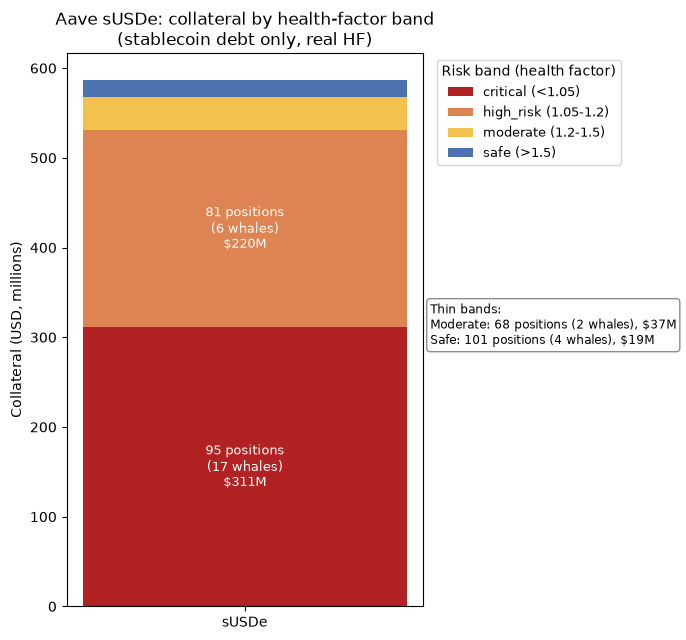

In [87]:
band_order = ["critical (<1.05)", "high_risk (1.05-1.2)", "moderate (1.2-1.5)", "safe (>1.5)"]
band_colors = {
    "critical (<1.05)": "#B22222",
    "high_risk (1.05-1.2)": "#DD8452",
    "moderate (1.2-1.5)": "#F2C14E",
    "safe (>1.5)": "#4C72B0",
}

values = aave_risk_summary["collateral_usd"] / 1e6
LABEL_INSIDE_THRESHOLD = 40

fig, ax = plt.subplots(figsize=(7, 6.5))
bottom = 0
thin_band_notes = []  # collect thin-segment details for a side text box instead of leader lines

for band in band_order:
    height = values[band]
    ax.bar(["sUSDe"], [height], bottom=bottom, label=band, color=band_colors[band])

    n_pos = int(aave_risk_summary.loc[band, "positions"])
    n_whale = int(aave_risk_summary.loc[band, "whale_positions"])
    label_text = f"{n_pos} positions ({n_whale} whales), ${height:.0f}M"

    if height > 0:
        if height >= LABEL_INSIDE_THRESHOLD:
            ax.annotate(
                f"{n_pos} positions\n({n_whale} whales)\n${height:.0f}M",
                xy=(0, bottom + height / 2), ha="center", va="center", fontsize=9,
                color="white" if band in ("critical (<1.05)", "high_risk (1.05-1.2)") else "black",
            )
        else:
            thin_band_notes.append(f"{band.split(' (')[0].title()}: {label_text}")

    bottom += height

ax.set_ylabel("Collateral (USD, millions)")
ax.set_title("Aave sUSDe: collateral by health-factor band\n(stablecoin debt only, real HF)")
ax.legend(title="Risk band (health factor)", loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)

# side text box for thin segments, placed below the legend
if thin_band_notes:
    note_text = "Thin bands:\n" + "\n".join(thin_band_notes)
    ax.text(1.02, 0.55, note_text, transform=ax.transAxes, fontsize=8.5,
            va="top", ha="left", bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray", alpha=0.9))

plt.tight_layout()
plt.savefig("../output/aave_risk_band_susde.png", dpi=300, bbox_inches="tight")
plt.show()

In [69]:
at_risk_aave = aave_risk_df[aave_risk_df["risk_band"].isin(["critical (<1.05)", "high_risk (1.05-1.2)"])]

n_whale = at_risk_aave["is_whale"].sum()
n_total = len(at_risk_aave)
usd_whale = at_risk_aave.loc[at_risk_aave["is_whale"], "collateral_value_usd"].sum()
usd_total = at_risk_aave["collateral_value_usd"].sum()

print(f"{n_whale} whale positions ({100*n_whale/n_total:.1f}% of {n_total} at-risk positions) "
      f"hold ${usd_whale:,.0f} of ${usd_total:,.0f} at-risk collateral "
      f"({100*usd_whale/usd_total:.1f}%)")

23 whale positions (13.1% of 176 at-risk positions) hold $515,395,088 of $531,109,882 at-risk collateral (97.0%)


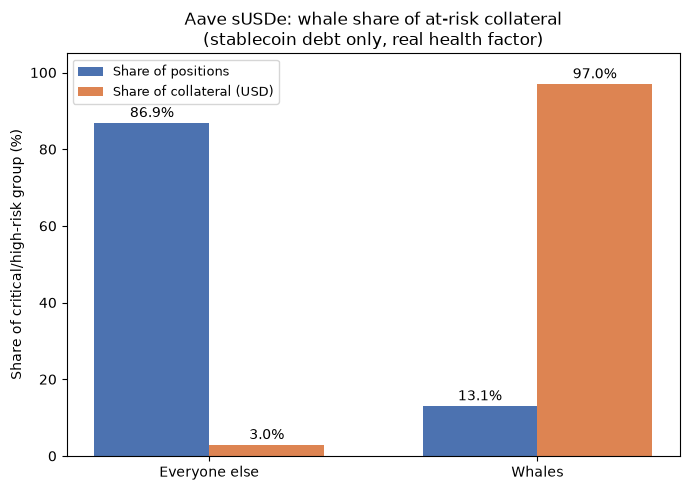

In [85]:
# Chart: same design as before, now sourced from at_risk_aave built on aave_risk_df
whale_summary = (
    at_risk_aave.groupby("is_whale")
    .agg(positions=("address", "count"), collateral_usd=("collateral_value_usd", "sum"))
    .reindex([False, True])
)

pct_positions = 100 * whale_summary["positions"] / whale_summary["positions"].sum()
pct_collateral = 100 * whale_summary["collateral_usd"] / whale_summary["collateral_usd"].sum()

labels = ["Everyone else", "Whales"]
x = np.arange(2)
width = 0.35

fig, ax = plt.subplots(figsize=(7, 5))
bars1 = ax.bar(x - width/2, pct_positions, width, label="Share of positions", color=BLUE)
bars2 = ax.bar(x + width/2, pct_collateral, width, label="Share of collateral (USD)", color=ORANGE)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.annotate(f"{bar.get_height():.1f}%", xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 4), textcoords="offset points", ha="center", fontsize=10)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Share of critical/high-risk group (%)")
ax.set_ylim(0, 105)
ax.set_title("Aave sUSDe: whale share of at-risk collateral\n(stablecoin debt only, real health factor)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("../output/aave_whale_risk_share.png", dpi=300, bbox_inches="tight")
plt.show()

In [62]:
print(f"{at_risk_aave['is_whale'].isna().sum()} rows with missing is_whale in at_risk_aave")

# treat missing as non-whale for now, but flag it so it's not silently lost
at_risk_aave = at_risk_aave.copy()
at_risk_aave["is_whale"] = at_risk_aave["is_whale"].fillna(False)

9 rows with missing is_whale in at_risk_aave


In [64]:
# Check for casing mismatch first (from the previous step, still unresolved)
print(repr(aave_borrowers["address"].iloc[0]))
print(repr(aave_risk_df["address"].iloc[0]))

# Normalize casing and re-merge is_whale cleanly
aave_borrowers["address"] = aave_borrowers["address"].str.lower()
aave_risk_df["address"] = aave_risk_df["address"].str.lower()

aave_risk_df = aave_risk_df.drop(columns=["is_whale"]).merge(
    aave_borrowers[["address", "is_whale"]].drop_duplicates(),
    on="address", how="left"
)

n_missing = aave_risk_df["is_whale"].isna().sum()
print(f"{n_missing} rows with missing is_whale after lowercase fix")

# force clean boolean dtype, defaulting any still-missing to False only if truly unresolvable
aave_risk_df["is_whale"] = aave_risk_df["is_whale"].fillna(False).astype(bool)
print(aave_risk_df["is_whale"].dtype)  # should now print bool

'0x0032d3bddf91d0af93ff26e209ede78b960e9c0f'
'0x0032d3bddf91d0af93ff26e209ede78b960e9c0f'
21 rows with missing is_whale after lowercase fix
bool


In [65]:
aave_stable_active_rows = aave_stable_raw[aave_stable_raw["borrowed_value"] > 0].merge(
    aave_risk_df[["address", "risk_band", "is_whale"]],
    on="address", how="inner"  # inner join naturally drops dust-debt / non-stablecoin-only wallets
)

at_risk_rows = aave_stable_active_rows[
    aave_stable_active_rows["risk_band"].isin(["critical (<1.05)", "high_risk (1.05-1.2)"])
]

stablecoins = {"USDT", "USDC", "USDe", "GHO", "USDS", "USDtb", "DAI", "PYUSD", "AUSD", "RLUSD", "msUSD"}

at_risk_by_debt_asset = (
    at_risk_rows[at_risk_rows["debt_symbol"].isin(stablecoins)]
    .groupby("debt_symbol")
    .agg(positions=("address", "count"),
         whale_positions=("is_whale", "sum"),
         debt_at_risk_usd=("borrowed_value", "sum"))
    .reset_index()
    .sort_values("debt_at_risk_usd", ascending=False)
)
at_risk_by_debt_asset

,debt_symbol,positions,whale_positions,debt_at_risk_usd
5,USDe,44,16,1.588684e+08
2,USDC,58,3,1.469484e+08
4,USDT,70,7,1.107932e+08
6,USDtb,2,1,5.931275e+06
1,GHO,3,0,6.018309e+05
3,USDS,1,0,7.202649e+04
0,DAI,1,0,2.375999e+01


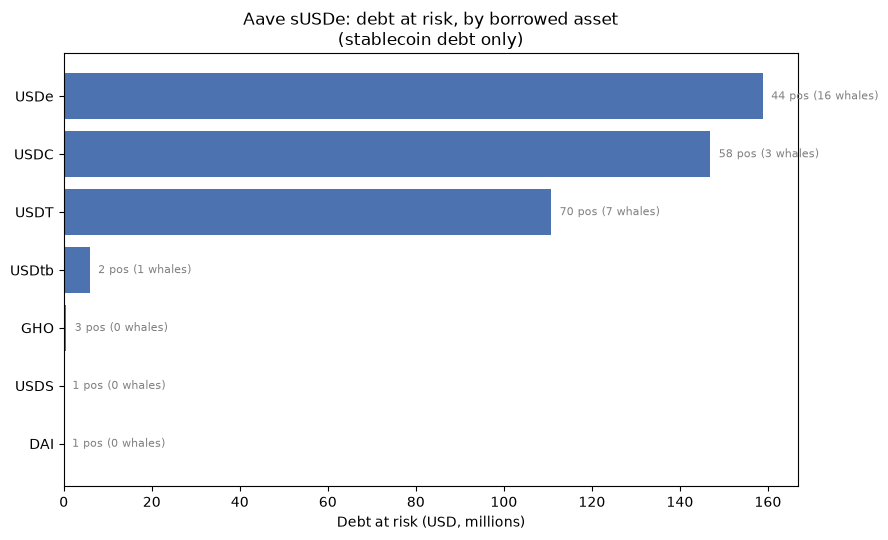

In [66]:
plot_data = at_risk_by_debt_asset.sort_values("debt_at_risk_usd", ascending=True)

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(plot_data["debt_symbol"], plot_data["debt_at_risk_usd"] / 1e6, color=BLUE)

for bar, pos, whale in zip(bars, plot_data["positions"], plot_data["whale_positions"]):
    ax.annotate(f"{pos} pos ({whale} whales)", xy=(bar.get_width(), bar.get_y() + bar.get_height()/2),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color="gray")

ax.set_xlabel("Debt at risk (USD, millions)")
ax.set_title("Aave sUSDe: debt at risk, by borrowed asset\n(stablecoin debt only)")
plt.tight_layout()
plt.savefig("../output/aave_at_risk_by_debt_asset.png", dpi=300, bbox_inches="tight")
plt.show()

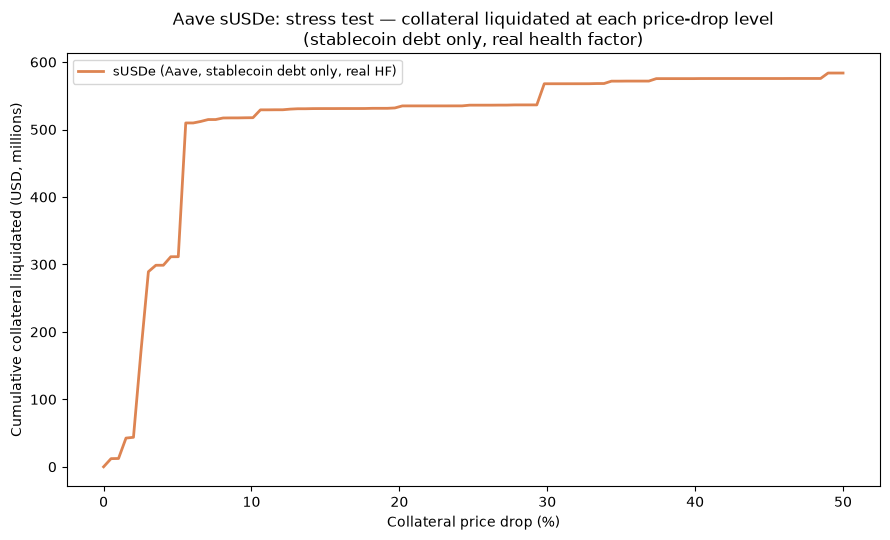

In [68]:
aave_risk_df["critical_shock"] = 1 - 1 / aave_risk_df["health_factor"]

shocks = np.linspace(0, 0.5, 100)

cumulative = [
    aave_risk_df.loc[aave_risk_df["critical_shock"] <= s, "collateral_value_usd"].sum() / 1e6
    for s in shocks
]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(shocks * 100, cumulative, color=ORANGE, linewidth=2, label="sUSDe (Aave, stablecoin debt only, real HF)")

ax.set_xlabel("Collateral price drop (%)")
ax.set_ylabel("Cumulative collateral liquidated (USD, millions)")
ax.set_title("Aave sUSDe: stress test — collateral liquidated at each price-drop level\n(stablecoin debt only, real health factor)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("../output/aave_price_shock_stress_test.png", dpi=300, bbox_inches="tight")
plt.show()